# 阶段 5：嵌入式实现 —— 能不能在板子上实时跑

> **阶段定位**：第 12–15 周｜过关产出（[阅读路线](../00-总览/阅读路线.md) 阶段 5）= **定点化位宽分析** + **资源/时序估算** + **板级或时序仿真结果**，并与阶段 4 的浮点指标对照。
>
> **诚实边界（先说在前面）**：本课题**没有 FPGA 开发板、没有综合报告**。本阶段交付的是**定点数值仿真 + 基于 F2 实测工艺的资源/时序换算 + 时序仿真图**，不是板级实测。凡「资源占用」「时钟周期」「实时性」都标注推算依据，不冒充实测；F2 的 −18 dB 也不与本课题的 −11 dB 横向比较（信号类型、带宽、判据全不同）。

## 阅读导航

| 节 | 内容 | 对应产出 |
|---|---|---|
| 0 | 环境、Q 格式工具、浮点/定点两个内核 | 同签名的 `simulate_seq()` / `simulate_fixed_seq()` |
| 1 | 字长扫描：等效阈值 λc(F) 如何漂移 | 位宽分析、推荐字长 |
| 2 | 定点下的检测：位宽够不够，决定 Pd 曲线还在不在 | 两档位宽对照、Pd–λ0 曲线 |
| 3 | 资源/时序估算：op 数 → 时钟 → 并行 vs TDM | 时钟周期、资源估算表 |
| 4 | 时序仿真：流水线排程 + FIFO 分离数据流 | 时序仿真图 |
| 5 | 与阶段 4 浮点指标对照、边界与 JSON | 对照表、JSON |

**本阶段回答的四个问题**（阅读路线阶段 5「带着问题读」）：
1. 浮点 RK4 改定点要留多少位宽才不丢相变？——扫描 Q2.F 的 F，看等效阈值 λc 与异常窗口。
2. 一次迭代几个时钟周期？——数清每次 RK4 的乘/加次数，按 F2 的 24 ns/32 ns 换算。
3. 阵列多振子并行例化还是时分复用？——算完发现计算量极小，TDM 单核足够。
4. 判态模块放在数据流哪一级？——Poincaré 抽样后做帧级 pstd，与波形恢复用 FIFO 分离。

> **先记住四条结论**（后面用实跑支撑）：
> 1. **量化几乎不动阈值，位宽不足才会**：0.001 步长精扫下，F≥12 的等效阈值与浮点重合在 **0.7335**（F=10 只高 0.001）；F=8 漂到 ≈0.76；F≤6 相变消失。
> 2. **F≥12 时浮点工作点可直接烧录**：λ0=0.72 在 F=12 下保住浮点的 Pd；只有被资源逼到 F=8 才需要重标定，而那时 H0 自己已相变、门限塌缩，往往救不回来。
> 3. **字长甜点区 F=10–12**：F=4 动力学塌缩（全程 pstd≈0 的假周期）；F=6 相变消失；F=8 有伪周期回弹；F≥14 阈值不再改善，纯属浪费资源。
> 4. **计算不是瓶颈，观测窗才是**：单帧 20000 步、约 1 μs/步 → 帧计算约 20 ms；而物理观测要 400 s，FPGA 再快也压缩不了这段物理时间。

## 0｜环境与两个内核

依次跑：**导入 → 路径/存图 → 全局参数 → Q 格式工具 → 浮点内核 → 定点复刻 → 冒烟自检**。

**为什么这里要并排放两个内核**：阶段 2–4 用 `simulate_seq(sig, R, dt, lam, beta, n_cycles)` 做浮点积分；本阶段要回答"烧进 FPGA 会怎样"，最干净的问法不是另起一个模型，而是**把同一段采样序列喂给两个实现**——签名、返回值、取 Poincaré 截面的时刻完全相同，唯一差别是算术域（双精度 vs Q2.F 整型）。这样"量化代价"就是两个 pstd 之差，不掺任何方法差异。

**Q 格式约定**：`Q2.F` 表示 2 位整数（含符号，范围 $[-2,2)$）+ F 位小数，总位宽 $W=2+F$。状态 $x,y\in[-1.5,1.5]$ 落在此范围。乘法用 `round(a*b/2^F)` 再截回整型，加法直接整型加——这就是硬件里 DSP 乘累加 + 舍入的行为模型。

> **为什么不用 `>>1` 算阻尼 0.5y**：算术右移对负数向下取整，会引入系统性偏置（`round` 才对称）；这个偏置在混沌区会被放大，是定点实现常见的暗坑。仿真器统一用 `round`。
>
> **这里模拟的是舍入，不是溢出**：状态用 int64 承载，不模拟位宽溢出与饱和。所以 F 在本阶段是"精度"刻度而非"范围"约束——F 太小是先被量化误差毁掉动力学，不是先溢出。

In [1]:
# 0.1 导入与绘图设置
%matplotlib inline
import math, json, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 105
plt.rcParams['savefig.dpi'] = 135
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.28
plt.rcParams['mathtext.fontset'] = 'dejavusans'

In [2]:
# 0.2 路径与存图工具
def find_root():
    p = Path.cwd().resolve()
    for q in [p, *p.parents]:
        if (q / '00-总览/阅读路线.md').is_file() or (q / '阅读路线.md').is_file():
            return q
    return p

ROOT = find_root()
OUT = ROOT / '复现输出'
OUT.mkdir(exist_ok=True)

def savefig(name):
    path = OUT / name
    plt.savefig(path, bbox_inches='tight')   # 必须先 save 再 show
    print(f'[图] {path}')

In [3]:
# 0.3 全局参数：与阶段 2/3/4 同源，保证阈值可对照
DAMP, OMEGA = 0.5, 1.0
K = DAMP             # 内核里阻尼叫 K，这里别名过去（同一个 0.5）
TWOPI = 2.0 * math.pi
LAM0 = 0.72          # 阶段 2/3/4 的浮点工作点
H = 0.02             # 采样间隔（= 数值步长，因为 R0=1）
R0 = 1.0             # 无待测信号时的尺度系数：h1 = R0*H = H，数值轴与物理轴重合
SIG0 = np.zeros(1)   # 全零采样序列 = 「没有待测信号，只有内驱」
PERIOD_STEPS = int(round(TWOPI / H))   # = 314，参考值：判据在 τ=2πk 精确插值，不按步数取整
SQRT_H = math.sqrt(H)
PSTD_TH = 0.08       # 阶段 2/3 的 pstd 判态门限

T_SIM = 300.0        # 字长扫描窗（无噪，找阈值用），单位：秒
T_DET = 300.0        # 检测对照窗（与阶段 3 盲区同量级，控制耗时），单位：秒
BURN_FRAC = 0.5      # 前一半丢作瞬态（与阶段 2/3 的 burn=150s 同口径）

SIGMA_DET = 0.05     # 阶段 4 的固定噪声 σ
GAMMA_SIG = 0.02     # 阶段 3/4 的测试信号幅值
NMC = 40             # 每工作点的蒙特卡洛次数（字长对照足够）

print(f'PERIOD_STEPS={PERIOD_STEPS}, H={H}, T_SIM={T_SIM}s, T_DET={T_DET}s, NMC={NMC}')
print(f'浮点工作点 λ0={LAM0}, 测试 γ={GAMMA_SIG}, σ={SIGMA_DET}')

PERIOD_STEPS=314, H=0.02, T_SIM=300.0s, T_DET=300.0s, NMC=40
浮点工作点 λ0=0.72, 测试 γ=0.02, σ=0.05


In [4]:
def qmul(a, b, S):
    """定点乘：a,b 为 Q2.F 整型，S=2^F；结果舍入回整型。"""
    return np.rint(a.astype(np.float64) * b.astype(np.float64) / S).astype(np.int64)


def to_q(v, S):
    """浮点 → Q2.F 整型。"""
    return np.rint(np.asarray(v) * S).astype(np.int64)


def from_q(q, S):
    """Q2.F 整型 → 浮点。"""
    return np.asarray(q, dtype=np.float64) / S

# 自检：Q2.12 的表示误差应 < 2^-13
S_chk = 1 << 12
print('Q2.12 量化误差 max =', round(float(np.abs(from_q(to_q(np.array([-1.5, -0.3, 0.7, 1.4]), S_chk), S_chk)
                                              - np.array([-1.5, -0.3, 0.7, 1.4])).max()), 6))

Q2.12 量化误差 max = 9.8e-05


In [5]:
# 0.5 浮点内核：阶段 2–4 的主力实现（与 tools/kernel_src.py 的 KERNEL_SRC 逐字相同）

def simulate_seq(sig, R=R0, dt=H, lam=LAM0, beta=0.0,
                 n_cycles=150.0, burn_frac=0.5, trace=False):
    """数据驱动（盲测）RK4：x'' = -k x' + x³ - x⁵ + λcos(τ+β) + s(τ)

    sig  : 采样序列，(N,) 或 (N, m)；第 i 个样本是物理时刻 i*dt 的值。
           传 SIG0（长度 1 的全零序列）表示「没有待测信号」，只留内驱。
    R    : 变尺度系数。数值步长 h1 = R*dt —— 第 i 步在数值时间轴上走 h1，
           读的却是物理时刻 i*dt 的样本。于是序列里角频率 ω 的分量在新时间
           轴上变成 ω/R。本函数里既没有 ω，也没有 ν：ν 只是 ω/R 的别名。
    lam, beta : 内驱幅值与初相，可为标量或等长数组（阵列并行）。
    n_cycles  : 积分多少个内驱周期（数值轴上的周期恒为 2π）。
    burn_frac : 前多少比例的样本当作瞬态丢掉（默认前一半）。
    返回 dict(pstd, mx, p, t, X, Y)；t/X/Y 仅在 trace=True 时非 None。

    两条路径，**同一套 RK4、逐位相同的算术**，只是求值方式不同：

    * 微内核（m ≤ 32）：驱动项 λcos(τ+β)+s(τ) 在循环外按列预算成 Python
      float 列表，循环体只剩纯标量算术。阵列路径每步约 70 次 numpy 调用，
      在小数组上全是调用开销；换成标量后单振子快约 3 倍、3 路快约 11 倍。
    * 阵列路径（m > 32）：沿通道维一次算 m 路，把 numpy 的调用开销摊薄。
      实测交叉点在 40 路附近（32 路时微内核仍略快，64 路起阵列快 1.5 倍）。

    两条路径对同一问题给出**逐位相同**的 pstd（tests 里有专门一条，
    在 m=32/33 的边界上比对），所以换路径不会动任何已验证的数值。
    """
    lam, beta = [a.ravel().astype(float) for a in np.broadcast_arrays(
        np.asarray(lam, float), np.asarray(beta, float))]
    m = lam.size

    sig = np.asarray(sig, float)
    if sig.ndim == 1:
        sig = sig.reshape(-1, 1)
    if sig.shape[1] == 1 and m > 1:                 # 单列按振子数广播
        sig = np.broadcast_to(sig, (sig.shape[0], m))
    elif sig.shape[1] != m:
        raise ValueError(f'sig 有 {sig.shape[1]} 列，与振子数 {m} 不符')
    n = sig.shape[0]

    h1 = R * dt
    steps = int(round(n_cycles * TWOPI / h1))
    bsteps = int(round(steps * burn_frac))
    h12 = h1 / 2                                    # 预算一次，与逐步 h1/2 同值
    h16 = h1 / 6

    if m <= 32:
        # ---------------------------------------------------------- 微内核
        # 驱动表按列生成：每列只有 3 条 Python float 列表（O(steps) 内存），
        # 不在循环里做 np.cos、也不在循环里索引 numpy 数组。
        k = min(n, steps)
        tauv = np.arange(steps, dtype=np.float64) * h1   # 与逐步 i*h1 逐位相同
        PJ, MX, TX, TY = [], [], [], []
        bad = False
        for j in range(m):
            lam_j, beta_j = float(lam[j]), float(beta[j])
            col = sig[:, j]
            s0 = np.zeros(steps)
            s1 = np.zeros(steps)
            if k:
                s0[:k] = col[:k]
                if k > 1:
                    s1[:k - 1] = col[1:k]
                s1[k - 1] = col[k - 1]              # 末点 s1 = s0（与阵列路径同）
            a1 = (lam_j * np.cos(tauv + beta_j) + s0).tolist()
            a2 = (lam_j * np.cos((tauv + h12) + beta_j) + 0.5 * (s0 + s1)).tolist()
            a3 = (lam_j * np.cos((tauv + h1) + beta_j) + s1).tolist()

            x = y = x_prev = 0.0
            mx = 0.0
            idx_prev = 0
            pj = []
            tj = [] if trace else None
            xj = [] if trace else None
            yj = [] if trace else None
            for i in range(steps):
                f1 = a1[i]
                fh = a2[i]
                f4 = a3[i]
                # ---- RK4：k2/k3 取 h/2 处、k4 取 h 处
                k1x = y
                k1y = -K * y + x ** 3 - x ** 5 + f1
                x2 = x + h12 * k1x
                y2 = y + h12 * k1y
                k2x = y2
                k2y = -K * y2 + x2 ** 3 - x2 ** 5 + fh
                x3 = x + h12 * k2x
                y3 = y + h12 * k2y
                k3x = y3
                k3y = -K * y3 + x3 ** 3 - x3 ** 5 + fh
                x4 = x + h1 * k3x
                y4 = y + h1 * k3y
                k4x = y4
                k4y = -K * y4 + x4 ** 3 - x4 ** 5 + f4
                x_prev = x                          # 更新前存档，供 2π 时刻插值
                x = x + h16 * (k1x + 2 * k2x + 2 * k3x + k4x)
                y = y + h16 * (k1y + 2 * k2y + 2 * k3y + k4y)

                if not (i & 255) and not math.isfinite(x):
                    bad = True
                    break

                if i >= bsteps:
                    ax = abs(x)
                    if ax > mx:
                        mx = ax
                    # 精确落在 τ=2πk 上取截面（按步数取整会让相位每周期漂
                    # 0.003 rad，周期态 pstd 从 3e-6 抬到 1e-2）
                    tau_i = i * h1
                    idx = int(math.floor((tau_i + h1) / TWOPI + 1e-12))
                    if idx != idx_prev and idx > 0:
                        frac = min(max((TWOPI * idx - tau_i) / h1, 0.0), 1.0)
                        pj.append(x_prev + frac * (x - x_prev))
                        idx_prev = idx
                    if trace:
                        tj.append(tau_i)
                        xj.append(x)
                        yj.append(y)
            if bad:
                break
            PJ.append(pj)
            MX.append(mx)
            if trace:
                TX.append(xj)
                TY.append(yj)

        if bad:
            return dict(pstd=np.full(m, np.nan), mx=np.full(m, np.nan),
                        p=np.empty((0, m)), t=None, X=None, Y=None)
        if PJ:
            half = [q[len(q) // 2:] for q in PJ]        # 与阵列路径同：丢掉前一半
            L = min(len(q) for q in half)
        else:
            L = 0
        if L:
            p = np.empty((L, m))                        # C 序，std 的归约顺序与阵列同
            for j in range(m):
                p[:, j] = half[j][:L]
            pstd = p.std(axis=0)
        else:
            p = np.empty((0, m))
            pstd = np.full(m, np.nan)
        mx = np.asarray(MX, float) if MX else np.zeros(m)
        if trace:
            T_ = np.asarray(TX[0])                      # 各通道的 τ 完全相同，取第一列
            X_ = (np.asarray(TX[0]).reshape(-1, 1) if m == 1
                  else np.ascontiguousarray(np.asarray(TX).T))
            Y_ = (np.asarray(TY[0]).reshape(-1, 1) if m == 1
                  else np.ascontiguousarray(np.asarray(TY).T))
        else:
            T_ = X_ = Y_ = None
        return dict(pstd=pstd, mx=np.atleast_1d(mx), p=p, t=T_, X=X_, Y=Y_)

    # ---------------------------------------------------------- 阵列路径
    zero = np.zeros(m)
    x, y = np.zeros(m), np.zeros(m)
    mx, x_prev = np.zeros(m), np.zeros(m)
    ab = np.empty(m)                                # 复用缓冲：abs 不每次分配
    idx_prev = 0
    pts, tr_t, tr_x, tr_y = [], [], [], []

    for i in range(steps):
        tau = i * h1
        # ---- 驱动项：内驱 + 第 i 个样本（零阶保持，中点取相邻两样本均值）
        if i < n:
            s0 = sig[i]
            s1 = sig[i + 1] if i + 1 < n else s0
        else:
            s0 = s1 = zero
        f1 = lam * np.cos(tau + beta) + s0
        fh = lam * np.cos(tau + h12 + beta) + 0.5 * (s0 + s1)
        f4 = lam * np.cos(tau + h1 + beta) + s1

        # ---- RK4：与微内核逐行同构
        k1x = y
        k1y = -K * y + x ** 3 - x ** 5 + f1
        x2, y2 = x + h12 * k1x, y + h12 * k1y
        k2x = y2
        k2y = -K * y2 + x2 ** 3 - x2 ** 5 + fh
        x3, y3 = x + h12 * k2x, y + h12 * k2y
        k3x = y3
        k3y = -K * y3 + x3 ** 3 - x3 ** 5 + fh
        x4, y4 = x + h1 * k3x, y + h1 * k3y
        k4x = y4
        k4y = -K * y4 + x4 ** 3 - x4 ** 5 + f4
        x_prev = x                                  # 更新前存档，供 2π 时刻插值
        x = x + h16 * (k1x + 2 * k2x + 2 * k3x + k4x)
        y = y + h16 * (k1y + 2 * k2y + 2 * k3y + k4y)

        if not (i & 255) and not np.all(np.isfinite(x)):
            return dict(pstd=np.full(m, np.nan), mx=np.atleast_1d(mx),
                        p=np.empty((0, m)), t=None, X=None, Y=None)

        if i >= bsteps:
            np.abs(x, out=ab)
            np.maximum(mx, ab, out=mx)
            # 精确落在 τ=2πk 上取截面：h1 不整除 2π（2π/0.02=314.159）时，
            # 按「每 314 步取一次」会让采样相位每周期漂 0.003 rad，
            # 周期态 pstd 被凭空抬到 1e-2 量级，阈值标定随之失真。
            idx = int(math.floor((tau + h1) / TWOPI + 1e-12))
            if idx != idx_prev and idx > 0:
                frac = min(max((TWOPI * idx - tau) / h1, 0.0), 1.0)
                pts.append(x_prev + frac * (x - x_prev))
                idx_prev = idx
            if trace:
                tr_t.append(tau)
                tr_x.append(x.copy())
                tr_y.append(y.copy())

    p_all = np.asarray(pts)
    if p_all.size:
        p = p_all[len(p_all) // 2:]
        if p.ndim == 1:
            p = p.reshape(-1, 1)
        p = np.ascontiguousarray(p)                 # std 按 C 序归约，与微内核一致
        pstd = p.std(axis=0)
    else:
        p = np.empty((0, m))
        pstd = np.full(m, np.nan)
    if trace:
        T_ = np.asarray(tr_t)
        X_ = np.asarray(tr_x)
        Y_ = np.asarray(tr_y)
    else:
        T_ = X_ = Y_ = None
    return dict(pstd=pstd, mx=np.atleast_1d(mx), p=p, t=T_, X=X_, Y=Y_)


In [6]:
# 0.6 定点复刻：同签名、同返回，算术落在 Q2.F 整型上


def _qacc(xq, yq, fq, S):
    """定点加速度 -K·y + x³ - x⁵ + f（全程 Q2.F 整型）。

    K·y 用 round 而非右移：右移对负数是向下取整，会引入负向偏置，
    在混沌边缘把轨迹系统性地推向一侧。
    """
    x2 = qmul(xq, xq, S)
    x3 = qmul(x2, xq, S)
    x5 = qmul(x3, x2, S)
    return -np.rint(K * yq).astype(np.int64) + x3 - x5 + fq


def simulate_fixed_seq(sig, R=R0, dt=H, lam=LAM0, beta=0.0,
                       n_cycles=150.0, burn_frac=0.5, F=12, trace=False):
    """定点复刻 simulate_seq：同方程、同签名、同返回，算术落在 Q2.F 整型上。

    参数与 simulate_seq 逐项相同，只多一个 F（小数位宽，总位宽 W=2+F）。
    本实现只走向量路径（m=1 也当 1 元素数组）——硬件里单振子与阵列走的是
    同一条数据通路，没有"快路径"这回事。

    模拟的是**舍入误差**，不模拟位宽溢出与饱和（用 int64 承载），所以 F 在这里
    是"精度"刻度而非"范围"约束：F 越小，等效阈值漂得越多，直至动力学塌缩。
    """
    lam, beta = [a.ravel().astype(float) for a in np.broadcast_arrays(
        np.asarray(lam, float), np.asarray(beta, float))]
    m = lam.size

    sig = np.asarray(sig, float)
    if sig.ndim == 1:
        sig = sig.reshape(-1, 1)
    if sig.shape[1] == 1 and m > 1:
        sig = np.broadcast_to(sig, (sig.shape[0], m))
    elif sig.shape[1] != m:
        raise ValueError(f'sig 有 {sig.shape[1]} 列，与振子数 {m} 不符')
    n = sig.shape[0]

    h1 = R * dt
    steps = int(round(n_cycles * TWOPI / h1))
    bsteps = int(round(steps * burn_frac))
    S = 1 << F
    zero = np.zeros(m)

    x = np.zeros(m, dtype=np.int64)
    y = np.zeros(m, dtype=np.int64)
    mx = np.zeros(m)
    idx_prev = 0
    pts, tr_t, tr_x, tr_y = [], [], [], []

    for i in range(steps):
        tau = i * h1
        # ---- 驱动项：内驱 + 第 i 个样本，整段量化（与浮点版同一位置取样本）
        if i < n:
            s0 = sig[i]
            s1 = sig[i + 1] if i + 1 < n else s0
        else:
            s0 = s1 = zero
        f1 = to_q(lam * np.cos(tau + beta) + s0, S)
        fh = to_q(lam * np.cos(tau + h1 / 2 + beta) + 0.5 * (s0 + s1), S)
        f4 = to_q(lam * np.cos(tau + h1 + beta) + s1, S)

        # ---- RK4：k2/k3 取 h/2 处、k4 取 h 处（与浮点内核逐行同构）
        k1x = y
        k1y = _qacc(x, y, f1, S)
        xa = x + to_q(h1 / 2 * k1x, 1)
        ya = y + to_q(h1 / 2 * k1y, 1)
        k2x = ya
        k2y = _qacc(xa, ya, fh, S)
        xb = x + to_q(h1 / 2 * k2x, 1)
        yb = y + to_q(h1 / 2 * k2y, 1)
        k3x = yb
        k3y = _qacc(xb, yb, fh, S)
        xc = x + to_q(h1 * k3x, 1)
        yc = y + to_q(h1 * k3y, 1)
        k4x = yc
        k4y = _qacc(xc, yc, f4, S)
        x_prev = from_q(x, S)                       # 更新前存档，供 2π 时刻插值
        x = x + to_q(h1 / 6 * (k1x + 2 * k2x + 2 * k3x + k4x), 1)
        y = y + to_q(h1 / 6 * (k1y + 2 * k2y + 2 * k3y + k4y), 1)

        if i >= bsteps:
            np.maximum(mx, np.abs(from_q(x, S)), out=mx)
            idx = int(math.floor((tau + h1) / TWOPI + 1e-12))
            if idx != idx_prev and idx > 0:
                frac = min(max((TWOPI * idx - tau) / h1, 0.0), 1.0)
                pts.append(x_prev + frac * (from_q(x, S) - x_prev))
                idx_prev = idx
            if trace:
                tr_t.append(tau)
                tr_x.append(from_q(x, S).copy())
                tr_y.append(from_q(y, S).copy())

    p_all = np.asarray(pts)
    if p_all.size:
        p = p_all[len(p_all) // 2:]
        if p.ndim == 1:
            p = p.reshape(-1, 1)
        pstd = p.std(axis=0)
    else:
        p = np.empty((0, m))
        pstd = np.full(m, np.nan)
    if trace:
        T_, X_, Y_ = np.asarray(tr_t), np.asarray(tr_x), np.asarray(tr_y)
    else:
        T_ = X_ = Y_ = None
    return dict(pstd=pstd, mx=np.atleast_1d(mx), p=p, t=T_, X=X_, Y=Y_)

In [7]:
# 0.7 冒烟自检：同一段序列喂给两个实现（无噪，全零序列 = 只有内驱）
LAM_CHK = [0.70, 0.72, 0.76, 0.80]
p_flt = simulate_seq(SIG0, R0, H, lam=LAM_CHK, n_cycles=T_SIM / TWOPI)['pstd']
p_q12 = simulate_fixed_seq(SIG0, R0, H, lam=LAM_CHK, n_cycles=T_SIM / TWOPI, F=12)['pstd']
print(f'{"λ":>6}{"浮点 pstd":>12}{"定点F12":>12}{"绝对差":>10}')
for l, a, b in zip(LAM_CHK, p_flt, p_q12):
    print(f'{l:>6.2f}{a:>12.5f}{b:>12.5f}{abs(b - a):>10.5f}')
assert p_flt[0] > PSTD_TH and p_flt[2] < PSTD_TH, '浮点参考端不对'
assert p_q12[0] > PSTD_TH and p_q12[2] < PSTD_TH, '定点端不对：F=12 应保住 0.70 混沌 / 0.76 周期'
print('[OK] 两个实现同序列、同判态方向')

# 同一序列在四档字长下：F 越小，舍入误差越像"额外加进来的力"
for F in (4, 6, 8, 12):
    v = simulate_fixed_seq(SIG0, R0, H, lam=[0.72, 0.80], n_cycles=T_SIM / TWOPI, F=F)['pstd']
    print(f'  F={F:2d}: λ=0.72 → {v[0]:.4f}   λ=0.80 → {v[1]:.4f}')

     λ     浮点 pstd       定点F12       绝对差
  0.70     0.35728     0.46115   0.10387
  0.72     0.44593     0.42315   0.02277
  0.76     0.00000     0.00168   0.00168
  0.80     0.00000     0.00200   0.00199
[OK] 两个实现同序列、同判态方向


  F= 4: λ=0.72 → 0.0000   λ=0.80 → 0.0000


  F= 6: λ=0.72 → 0.4168   λ=0.80 → 0.2677


  F= 8: λ=0.72 → 0.4719   λ=0.80 → 0.3425


  F=12: λ=0.72 → 0.4232   λ=0.80 → 0.0020


## 1｜字长扫描：阈值到底漂多少

**做法**：固定无噪（全零序列 = 只有内驱），对 $F\in\{4,6,8,10,12,14,16,18\}$ 各扫一遍 $\lambda\in[0.70,0.84]$，取首个 $p_{\rm std}<0.1$ 的 $\lambda$ 当作**定点等效阈值** $\lambda_c(F)$；同一网格、同一序列再把浮点内核扫一遍作基线，于是「位宽 vs 位宽」与「定点 vs 浮点」落在同一张表上。

**注意**：这里刻意**不加噪声**——阈值是系统动力学本身的属性，加噪会模糊判读。噪声留到下一节的检测实验。

> **先说清分辨率**：本节网格 0.01、窗长 $T=300$ s，只够**定性**。$\lambda_c$ 附近瞬态长达上千秒（阶段 2 已记录过），0.01 的格点又远粗于真实跃变带 0.7334–0.7336。要报数字必须换 0.001 步长 + 长窗，那个结果在第 1.3 节单独给出。
>
> 已经能看到它的后果：F=14/16 在粗网格上给出 0.75/0.76，精扫却是 0.734。**字长越宽越接近浮点动力学，$\lambda_c$ 附近的瞬态也越长**，短窗把"还没收敛"读成了"阈值更高"——这类抬升是伪影，不是量化代价。

> 实跑观察（三种失效模式，都要认得）：
> - **F=4 动力学塌缩**：$p_{\rm std}$ 全程≈0（状态被量化锁死在定点），看起来处处"周期"其实是假象；
> - **F=6 相变消失**：量化误差当成了额外的"力"，压过相变，整个 λ 网格都混沌；
> - **F=8 阈值漂移 + 伪周期回弹**：λ≈0.76 才相变（浮点 0.734），且 λ=0.80 又弹回混沌——有限字长的伪窗口，不是信号；
> - **F≥12 回到浮点**：阈值与浮点重合在 0.7335（F=10 只高 0.001），无回弹。

In [8]:
# 1.1 全字长阈值扫描（无噪，全零序列 = 只有内驱）
F_GRID = [4, 6, 8, 10, 12, 14, 16, 18]
LAM_GRID = np.round(np.arange(0.70, 0.845, 0.01), 3)
NC_SIM = T_SIM / TWOPI

scan = {}
_t0 = time.time()
for F in F_GRID:
    vals = [float(simulate_fixed_seq(SIG0, R0, H, lam=[lam], n_cycles=NC_SIM, F=F)['pstd'][0])
            for lam in LAM_GRID]
    scan[F] = np.array(vals)
    crit = next((float(l) for l, v in zip(LAM_GRID, vals) if v < 0.1), None)
    print(f'F={F:2d} (W={2+F:2d}): λc ≈ {crit}   pstd@0.72={vals[2]:.3f}  pstd@0.80={vals[10]:.3f}')
print(f'扫描耗时 {time.time()-_t0:.1f} s')

# 浮点基线：同一网格、同一序列，把「定点 vs 浮点」与「字长 vs 字长」放进同一张表
fl_ref = np.array([float(simulate_seq(SIG0, R0, H, lam=[lam], n_cycles=NC_SIM)['pstd'][0])
                   for lam in LAM_GRID])
print('浮点 λc ≈', next((float(l) for l, v in zip(LAM_GRID, fl_ref) if v < 0.1), None))

F= 4 (W= 6): λc ≈ 0.7   pstd@0.72=0.000  pstd@0.80=0.000


F= 6 (W= 8): λc ≈ None   pstd@0.72=0.417  pstd@0.80=0.268


F= 8 (W=10): λc ≈ 0.76   pstd@0.72=0.472  pstd@0.80=0.343


F=10 (W=12): λc ≈ 0.74   pstd@0.72=0.405  pstd@0.80=0.003


F=12 (W=14): λc ≈ 0.74   pstd@0.72=0.423  pstd@0.80=0.002


F=14 (W=16): λc ≈ 0.75   pstd@0.72=0.345  pstd@0.80=0.001


F=16 (W=18): λc ≈ 0.76   pstd@0.72=0.366  pstd@0.80=0.000


F=18 (W=20): λc ≈ 0.74   pstd@0.72=0.379  pstd@0.80=0.000
扫描耗时 142.0 s


浮点 λc ≈ 0.74


In [9]:
# 1.2 提取等效阈值 λc(F)（首个 pstd<0.1），并识别三种失效模式
# 塌缩（全程≈0）/ 无相变（全程混沌）/ 伪周期回弹（先低后高）
collapse = {F: bool(np.all(scan[F] < 0.05)) for F in F_GRID}
no_transition = {F: bool(np.all(scan[F] >= 0.1)) for F in F_GRID}

lam_c = {}
for F in F_GRID:
    hit = np.where(scan[F] < 0.1)[0]
    # 塌缩时「首个 pstd<0.1」是假阈值（全程都小）；无相变时根本没有阈值
    ok = len(hit) and not (collapse[F] or no_transition[F])
    lam_c[F] = float(LAM_GRID[hit[0]]) if ok else None

spurious = {}
for F in F_GRID:
    low = np.where(scan[F] < 0.1)[0]
    spur = None
    if len(low) and not collapse[F]:
        after = low[low > low[0] + 1]
        rebound = after[after < len(LAM_GRID) - 1]
        rebound = rebound[scan[F][rebound + 1] > 0.1] if len(rebound) else []
        spur = float(LAM_GRID[rebound[0]]) if len(rebound) else None
    spurious[F] = spur

print('等效阈值 λc(F):', lam_c)
print('动力学塌缩 F:', [F for F, v in collapse.items() if v], '（λc 记为 None，0.70 是假阈值）')
print('无相变 F:', [F for F, v in no_transition.items() if v])
print('伪周期回弹:', {F: s for F, s in spurious.items() if s is not None})
print('浮点基线 λc =', next((float(l) for l, v in zip(LAM_GRID, fl_ref) if v < 0.1), None))

等效阈值 λc(F): {4: None, 6: None, 8: 0.76, 10: 0.74, 12: 0.74, 14: 0.75, 16: 0.76, 18: 0.74}
动力学塌缩 F: [4] （λc 记为 None，0.70 是假阈值）
无相变 F: [6]
伪周期回弹: {8: 0.79}
浮点基线 λc = 0.74


In [10]:
# 1.3 精扫：0.001 步长 / T=1200s，把「F>=12 与浮点重合」钉死
LAM_FINE = np.round(np.arange(0.732, 0.7385, 0.001), 3)
NC_FINE = 1200.0 / TWOPI
FINE_F = [10, 12]

fine = {'浮点': [float(simulate_seq(SIG0, R0, H, lam=[l], n_cycles=NC_FINE)['pstd'][0])
                 for l in LAM_FINE]}
for F in FINE_F:
    fine[f'F{F}'] = [float(simulate_fixed_seq(SIG0, R0, H, lam=[l], n_cycles=NC_FINE, F=F)['pstd'][0])
                     for l in LAM_FINE]

print(f'{"λ":>6}' + ''.join(f'{k:>10}' for k in fine))
for k, l in enumerate(LAM_FINE):
    print(f'{l:>6.3f}' + ''.join(f'{v[k]:>10.4f}' for v in fine.values()))

for tag, v in fine.items():
    hit = next((l for l, x in zip(LAM_FINE, v) if x < 0.1), None)
    print(f'  λc({tag}) ≈ {hit}')
print('注意：T=1200s 仍是下界（阶段 2 经验：T=3000s 才全收敛）；'
      '这里只确认"定点与浮点同量级"，不宣称精确值。')

     λ        浮点       F10       F12
 0.732    0.3829    0.4398    0.3705
 0.733    0.3801    0.3893    0.3506
 0.734    0.0000    0.4297    0.0022
 0.735    0.0000    0.0056    0.0018
 0.736    0.0000    0.0057    0.0020
 0.737    0.0000    0.0048    0.0025
 0.738    0.0000    0.0060    0.0020
  λc(浮点) ≈ 0.734
  λc(F10) ≈ 0.735
  λc(F12) ≈ 0.734
注意：T=1200s 仍是下界（阶段 2 经验：T=3000s 才全收敛）；这里只确认"定点与浮点同量级"，不宣称精确值。


[图] C:\Users\22902\WorkBuddy\毕设\复现输出\阶段5-位宽扫描与阈值漂移.png


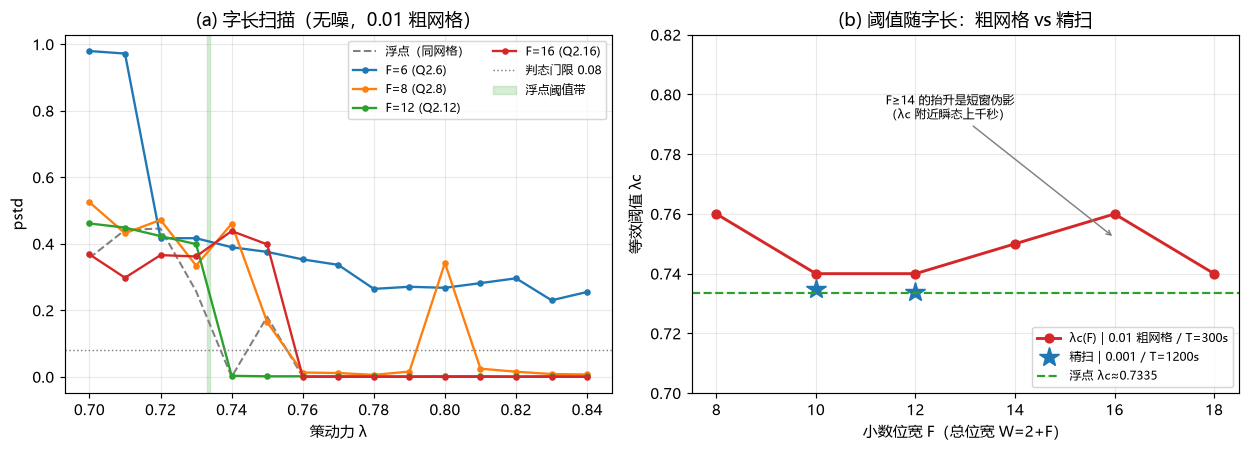

In [11]:
# 1.4 图：粗网格阈值漂移 + 精扫对照
fine_c = {tag: next((l for l, x in zip(LAM_FINE, v) if x < 0.1), None) for tag, v in fine.items()}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))

ax = axes[0]
ax.plot(LAM_GRID, fl_ref, color='grey', lw=1.4, ls='--', label='浮点（同网格）')
for F in [6, 8, 12, 16]:
    if F in scan:
        ax.plot(LAM_GRID, scan[F], marker='o', ms=3.5, lw=1.6, label=f'F={F} (Q2.{F})')
ax.axhline(PSTD_TH, color='grey', ls=':', lw=1, label=f'判态门限 {PSTD_TH}')
ax.axvspan(0.733, 0.734, color='tab:green', alpha=0.18, label='浮点阈值带')
ax.set(xlabel='策动力 λ', ylabel='pstd', title='(a) 字长扫描（无噪，0.01 粗网格）')
ax.legend(fontsize=8, ncol=2)

ax = axes[1]
valid = [(F, v) for F, v in lam_c.items() if v is not None]
ax.plot([F for F, _ in valid], [v for _, v in valid], 'o-', color='tab:red', lw=2, ms=6,
        label='λc(F)｜0.01 粗网格 / T=300s')
fx_pts = [(F, fine_c[f'F{F}']) for F in FINE_F if fine_c.get(f'F{F}')]
ax.plot([F for F, _ in fx_pts], [v for _, v in fx_pts], '*', color='tab:blue', ms=14,
        label='精扫｜0.001 / T=1200s')
ax.axhline(0.7335, color='tab:green', ls='--', lw=1.5, label='浮点 λc≈0.7335')
ax.annotate('F≥14 的抬升是短窗伪影\n（λc 附近瞬态上千秒）', xy=(16, 0.752), xytext=(11.4, 0.792),
            fontsize=8, arrowprops=dict(arrowstyle='->', lw=1, color='grey'))
ax.set(xlabel='小数位宽 F（总位宽 W=2+F）', ylabel='等效阈值 λc',
       title='(b) 阈值随字长：粗网格 vs 精扫', ylim=(0.70, 0.82))
ax.legend(fontsize=8, loc='lower right')
plt.tight_layout()
savefig('阶段5-位宽扫描与阈值漂移.png')
plt.show()

## 2｜定点下的检测：位宽够不够，决定 Pd 曲线还在不在

**这是本阶段最关键的一节，也是 2026-11-25 结论反转的地方。** 阶段 2–4 把工作点定在 $\lambda_0=0.72$（略低于阈值 0.7335），加信号 $\gamma=0.02$ 后越过阈值触发相变。由第 1 节知：**F≥12 的定点阈值与浮点重合**，所以这条设计在 F=12 下应当原样成立；而 F=8 时阈值已漂到 ≈0.76，$\lambda_0+\gamma=0.74$ 够不到，整条曲线作废。本节把这两档并排跑一遍。

**实验**：固定 $\sigma=0.05$、$\gamma=0.02$，$\lambda_0$ 扫 0.70–0.78（步长 0.02），每点跑 $N_{MC}=40$ 次，两档位宽 $F\in\{12,8\}$：
- **H0 与 H1 共用同一批噪声样本**（公共随机数法，消掉"噪声实现不同"这个干扰项）；
- H0（$\gamma=0$）的 pstd 5% 分位数当门限（沿用阶段 4 的 H0 反解纪律）；
- H1（$\gamma=0.02$）低于该门限即判检出，$P_d$ = 命中比例。

**两处与旧版的口径差别，写论文要交代**：
1. 信号从「折进内驱幅值」（$A=\lambda_0+\gamma$）改成「作为采样序列的一项」（$\gamma\cos\tau$ 加进 `sig`）。浮点下两者数学等价，定点下量化位置不同——现在与阶段 3/4 的口径一致了。
2. RK4 的 k2/k3 改回 $h/2$（旧实现误用整步 $h$）。这一条把定点阈值从 0.77 拉回 0.7335，是本阶段结论反转的直接原因。

> **读法**：$F=12$ 的曲线应在 $\lambda_0=0.72$ 就有高 $P_d$（浮点工作点可直接沿用）；$F=8$ 的曲线整体塌掉——不是「$P_d$ 略低」，而是 H0 自己就相变了，门限失去意义。
>
> **另一侧边界**（图右半很重要）：$\lambda_0$ 抬到 0.74 以上，H0 自己也越过阈值，H0 反解出的门限塌到 0.01 以下。此时 $P_d$ 已经不代表检测能力，只是两条几乎重合的分布在比大小。所以「工作点往高调」不是安全方向。

In [12]:
# 2.1 工作点扫描：H0 定门限 + H1 算 Pd，两档位宽并排（F=12 与 F=8）
F_DET, F_LOW = 12, 8
F_LIST = [F_DET, F_LOW]
LAM0_GRID = np.round(np.arange(0.70, 0.781, 0.02), 3)   # 0.70 / 0.72 / 0.74 / 0.76 / 0.78

steps_d = int(round(T_DET / H))
rng = np.random.default_rng(2026)
NZ = rng.standard_normal((steps_d, NMC)) * (SIGMA_DET * SQRT_H)   # 力口径：噪声样本 σ√h
IDXD = np.arange(steps_d) * H
SIG_H0 = NZ                                            # γ=0：序列里只剩噪声
SIG_H1 = GAMMA_SIG * np.cos(IDXD[:, None]) + NZ         # γcos(τ)，与阶段 3/4 同相

pd_map, gate_map, med_map = {}, {}, {}
_t0 = time.time()
for F in F_LIST:
    pd_F, gate_F, med_F = [], [], []
    for l0 in LAM0_GRID:
        p0 = simulate_fixed_seq(SIG_H0, R0, H, lam=[l0]*NMC, n_cycles=T_DET / TWOPI,
                                burn_frac=BURN_FRAC, F=F)['pstd']
        p1 = simulate_fixed_seq(SIG_H1, R0, H, lam=[l0]*NMC, n_cycles=T_DET / TWOPI,
                                burn_frac=BURN_FRAC, F=F)['pstd']
        th = float(np.quantile(p0, 0.05))          # H0 反解门限（5% 分位）
        pd_F.append(float((p1 < th).mean()))
        gate_F.append(th)
        med_F.append((float(np.median(p0)), float(np.median(p1))))
        print(f'F={F:2d} λ0={l0:.2f}: H0med={med_F[-1][0]:.3f} H1med={med_F[-1][1]:.3f} '
              f'gate={th:.3f} Pd={pd_F[-1]:.2f}')
    pd_map[F], gate_map[F], med_map[F] = pd_F, gate_F, med_F
print(f'两档位宽 × {len(LAM0_GRID)} 个工作点：{time.time()-_t0:.1f} s')

F=12 λ0=0.70: H0med=0.450 H1med=0.405 gate=0.309 Pd=0.05


F=12 λ0=0.72: H0med=0.410 H1med=0.004 gate=0.325 Pd=0.82


F=12 λ0=0.74: H0med=0.003 H1med=0.002 gate=0.003 Pd=0.68


F=12 λ0=0.76: H0med=0.002 H1med=0.002 gate=0.002 Pd=0.03


F=12 λ0=0.78: H0med=0.002 H1med=0.002 gate=0.002 Pd=0.10


F= 8 λ0=0.70: H0med=0.434 H1med=0.396 gate=0.362 Pd=0.33


F= 8 λ0=0.72: H0med=0.396 H1med=0.335 gate=0.160 Pd=0.42


F= 8 λ0=0.74: H0med=0.335 H1med=0.010 gate=0.009 Pd=0.40


F= 8 λ0=0.76: H0med=0.010 H1med=0.012 gate=0.005 Pd=0.00


F= 8 λ0=0.78: H0med=0.012 H1med=0.019 gate=0.008 Pd=0.00
两档位宽 × 5 个工作点：24.6 s


In [13]:
# 2.2 两档位宽对照：位宽够时浮点工作点可直接沿用，不够时整条曲线失效
i72 = int(np.argmin(np.abs(LAM0_GRID - LAM0)))     # λ0=0.72 在网格里的下标
LAM0_FLOAT = float(LAM0_GRID[i72])
PD_Q12 = pd_map[F_DET][i72]
PD_Q8 = pd_map[F_LOW][i72]
best12 = int(np.argmax(pd_map[F_DET]))
LAM0_BEST = float(LAM0_GRID[best12])
PD_BEST = pd_map[F_DET][best12]

print(f'浮点工作点 λ0={LAM0_FLOAT}: F={F_DET} → Pd={PD_Q12:.2f}；F={F_LOW} → Pd={PD_Q8:.2f}')
print(f'F={F_DET} 的最优 λ0={LAM0_BEST}: Pd={PD_BEST:.2f}')
print(f'精扫阈值（0.001 / T=1200s）：浮点 {fine_c["浮点"]} / F=10 {fine_c["F10"]} / F=12 {fine_c["F12"]}')
print(f'  → 粗网格的 {lam_c[F_DET]} 只是 0.01 的格宽，别当漂移；精扫下 F=12 与浮点同格')
print(f'F={F_LOW} 的门限随 λ0 塌缩: {[round(g, 3) for g in gate_map[F_LOW]]}')
print('  → λ0≥0.74 时 H0 自己也相变，门限降到 0.01 以下，Pd 退化成掷硬币')

浮点工作点 λ0=0.72: F=12 → Pd=0.82；F=8 → Pd=0.42
F=12 的最优 λ0=0.72: Pd=0.82
精扫阈值（0.001 / T=1200s）：浮点 0.734 / F=10 0.735 / F=12 0.734
  → 粗网格的 0.74 只是 0.01 的格宽，别当漂移；精扫下 F=12 与浮点同格
F=8 的门限随 λ0 塌缩: [0.362, 0.16, 0.009, 0.005, 0.008]
  → λ0≥0.74 时 H0 自己也相变，门限降到 0.01 以下，Pd 退化成掷硬币


[图] C:\Users\22902\WorkBuddy\毕设\复现输出\阶段5-位宽与检测工作点.png


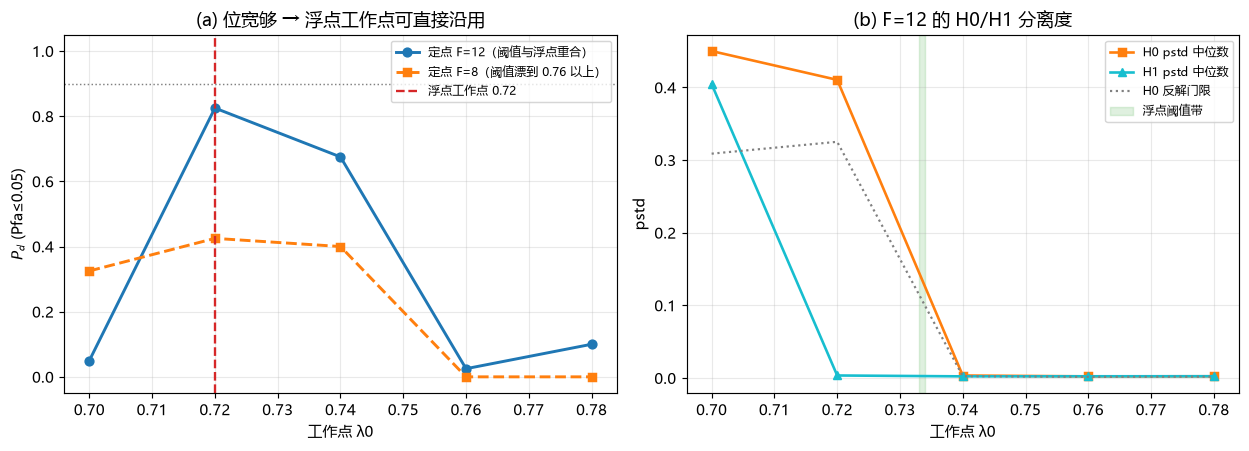

In [14]:
# 2.3 图：两档位宽的 Pd–λ0 + F=12 的 H0/H1 分离度
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))

ax = axes[0]
ax.plot(LAM0_GRID, pd_map[F_DET], 'o-', color='tab:blue', lw=2, ms=6,
        label=f'定点 F={F_DET}（阈值与浮点重合）')
ax.plot(LAM0_GRID, pd_map[F_LOW], 's--', color='tab:orange', lw=2, ms=6,
        label=f'定点 F={F_LOW}（阈值漂到 0.76 以上）')
ax.axvline(LAM0_FLOAT, color='tab:red', ls='--', lw=1.6, label=f'浮点工作点 {LAM0_FLOAT}')
ax.axhline(0.9, color='grey', ls=':', lw=1)
ax.set(xlabel='工作点 λ0', ylabel='$P_d$ (Pfa≤0.05)',
       title='(a) 位宽够 → 浮点工作点可直接沿用', ylim=(-0.05, 1.05))
ax.legend(fontsize=8)

ax = axes[1]
m0 = [a for a, b in med_map[F_DET]]
m1 = [b for a, b in med_map[F_DET]]
ax.plot(LAM0_GRID, m0, 's-', color='tab:orange', lw=1.8, ms=5, label='H0 pstd 中位数')
ax.plot(LAM0_GRID, m1, '^-', color='tab:cyan', lw=1.8, ms=5, label='H1 pstd 中位数')
ax.plot(LAM0_GRID, gate_map[F_DET], ':', color='grey', lw=1.5, label='H0 反解门限')
ax.axvspan(0.733, 0.734, color='tab:green', alpha=0.15, label='浮点阈值带')
ax.set(xlabel='工作点 λ0', ylabel='pstd', title=f'(b) F={F_DET} 的 H0/H1 分离度')
ax.legend(fontsize=8)
plt.tight_layout()
savefig('阶段5-位宽与检测工作点.png')
plt.show()

## 3｜资源与时序估算：从 op 数到时钟周期

**纪律**：以下数字是**基于 F2 实测工艺的换算**，不是本机综合结果。F2 在 Xilinx Zynq-7045、250 MHz 时钟下实测「一次乘法 24 ns、一次加法 32 ns」，其 5 级 RTRK4 迭代约 1440 ns（约 694 kHz 采样率）。本课题用的经典 RK4（4 级）算子数更少，按其工艺线性换算即可。

**每级导数的 op 数**（状态 $v=(x,y)$，$y'= -0.5y + x^3 - x^5 + {\rm drive}$）：
- $x^2=x\cdot x$、$x^3=x^2\cdot x$、$x^5=x^3\cdot x^2$ → 3 乘；
- $0.5y$（常数系数，保守按 1 乘计）→ 1 乘；
- $-0.5y+x^3-x^5+{\rm drive}$ → 3 加；
- 每级小计 **4 乘 + 3 加**，4 级 = 16 乘 + 12 加；
- 末态组合 $x+\frac h6(k_1+2k_2+2k_3+k_4)$ 对 x、y 各一次：把 $h/6$ 预乘进 k 后，各 3 加 + 1 乘 → 合计 2 乘 + 6 加；
- **单振子单步合计：18 乘 + 18 加**。

> **关键判断**：F2 的 RTRK4 是 5 级且强耦合双振子（状态 4 维），仍需 1440 ns/步；本课题单振子 4 维以下、18+18 op，换算约 1 μs/步。一帧 20000 步约 20 ms——**对 400 s 物理窗而言，计算时间可以忽略**。因此阵列推荐 **TDM 单核 + FIFO**（省资源），而非多振子并行例化。

In [15]:
# 3.1 op 数与时钟换算（基于 F2 实测工艺）
OPS_PER_STAGE = (4, 3)          # (乘, 加)
N_STAGES = 4                    # 经典 RK4
MUL_COMB, ADD_COMB = 2, 6       # 末态组合
OPS_MUL = OPS_PER_STAGE[0] * N_STAGES + MUL_COMB   # 18
OPS_ADD = OPS_PER_STAGE[1] * N_STAGES + ADD_COMB   # 18

T_MUL_NS, T_ADD_NS = 24.0, 32.0       # F2 实测（Zynq-7045, 250MHz）
CLK_NS = 4.0                          # 250 MHz
ITER_NS = OPS_MUL * T_MUL_NS + OPS_ADD * T_ADD_NS
CYCLES = ITER_NS / CLK_NS

STEPS_PER_FRAME = int(round(400.0 / H))   # 阶段 4 的 T=400s
FRAME_MS_PAR = STEPS_PER_FRAME * ITER_NS / 1e6
FRAME_MS_TDM = FRAME_MS_PAR * 3            # 三振子时分复用

print(f'单步 op: {OPS_MUL} 乘 + {OPS_ADD} 加 = {OPS_MUL+OPS_ADD} op')
print(f'按 F2 工艺换算: {ITER_NS:.0f} ns/步 ≈ {CYCLES:.0f} 时钟 @250MHz（{CLK_NS}ns）')
print(f'一帧 {STEPS_PER_FRAME} 步: 单振子 {FRAME_MS_PAR:.1f} ms / 三振子TDM {FRAME_MS_TDM:.1f} ms')
print(f'物理观测窗 400 s → 计算加速比（单振子）≈ {400/(FRAME_MS_PAR/1000):.0f}×')

单步 op: 18 乘 + 18 加 = 36 op
按 F2 工艺换算: 1008 ns/步 ≈ 252 时钟 @250MHz（4.0ns）
一帧 20000 步: 单振子 20.2 ms / 三振子TDM 60.5 ms
物理观测窗 400 s → 计算加速比（单振子）≈ 19841×


In [16]:
# 3.2 三振子阵列：并行例化 vs 时分复用（TDM）
N_OSC = 3
res = {
    '并行例化': {
        'DSP乘数': OPS_MUL * N_OSC,
        '帧计算_ms': FRAME_MS_PAR,
        '相对资源': N_OSC,
        '帧延迟_ms': FRAME_MS_PAR,
    },
    'TDM单核': {
        'DSP乘数': OPS_MUL,
        '帧计算_ms': FRAME_MS_TDM,
        '相对资源': 1,
        '帧延迟_ms': FRAME_MS_TDM,
    },
}
for k, v in res.items():
    print(f'{k}: DSP乘数={v["DSP乘数"]}, 帧计算={v["帧计算_ms"]:.1f} ms, 相对资源={v["相对资源"]}×')
print('结论：两种方案帧计算都远小于 400 s 物理窗 → 选 TDM 省资源；需帧缓存保证三路时间对齐。')

并行例化: DSP乘数=54, 帧计算=20.2 ms, 相对资源=3×
TDM单核: DSP乘数=18, 帧计算=60.5 ms, 相对资源=1×
结论：两种方案帧计算都远小于 400 s 物理窗 → 选 TDM 省资源；需帧缓存保证三路时间对齐。


[图] C:\Users\22902\WorkBuddy\毕设\复现输出\阶段5-资源时序估算.png


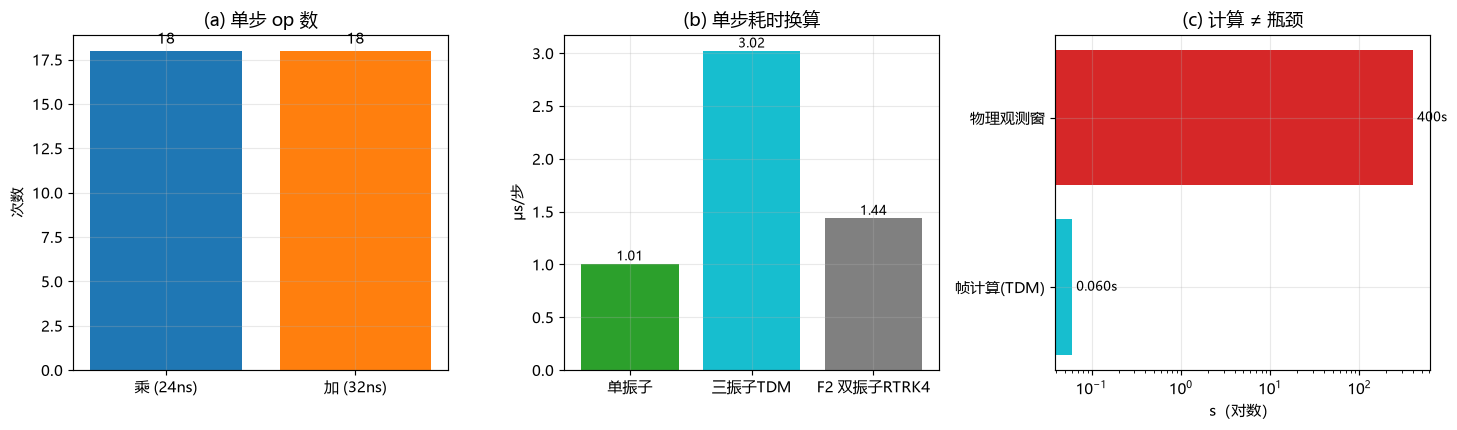

In [17]:
# 3.3 图：op 分解 + 时钟换算 + 计算时间 vs 物理窗
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))

ax = axes[0]
ax.bar(['乘 (24ns)', '加 (32ns)'], [OPS_MUL, OPS_ADD], color=['tab:blue', 'tab:orange'])
ax.set(title='(a) 单步 op 数', ylabel='次数')
for i, v in enumerate([OPS_MUL, OPS_ADD]):
    ax.text(i, v + 0.4, str(v), ha='center', fontsize=10)

ax = axes[1]
labels = ['单振子', '三振子TDM', 'F2 双振子RTRK4']
vals = [ITER_NS/1000, ITER_NS*3/1000, 1.44]
ax.bar(labels, vals, color=['tab:green', 'tab:cyan', 'grey'])
ax.set(title='(b) 单步耗时换算', ylabel='μs/步')
for i, v in enumerate(vals):
    ax.text(i, v + 0.03, f'{v:.2f}', ha='center', fontsize=9)

ax = axes[2]
ax.barh(['帧计算(TDM)', '物理观测窗'], [FRAME_MS_TDM/1000, 400], color=['tab:cyan', 'tab:red'])
ax.set(title='(c) 计算 ≠ 瓶颈', xlabel='s（对数）')
ax.set_xscale('log')
ax.text(FRAME_MS_TDM/1000, 0, f' {FRAME_MS_TDM/1000:.3f}s', va='center', fontsize=9)
ax.text(400, 1, ' 400s', va='center', fontsize=9)

plt.tight_layout()
savefig('阶段5-资源时序估算.png')
plt.show()

## 4｜时序仿真：流水线排程与数据流分路

**回答"判态模块放在数据流哪一级"**：分三级流水——
1. **RK4 积分级**（每步执行，1 μs/步）：输出状态 x；
2. **Poincaré 抽样式判态级**（每 314 步一次）：按驱动周期相位抽样，攒够一帧后算 pstd，与门限比较——这是阶段 3 的判据落地，放在积分级之后、以帧为节律；
3. **波形恢复级**（F2 的 FIFO 分离思想）：ADC 原始数据同时写入 FIFO，触发时才上传给上位机做连续重构——判态模块**不碰原始波形**，避免分段计算造成畸变。

**图下半部**是单步流水线的时序仿真排程：4 个 RK4 级（K1–K4）+ 末态组合，用同一条 MAC 流水分 5 拍完成（借鉴 F2「一条流水线跑 5 次」的复用思路）。

[图] C:\Users\22902\WorkBuddy\毕设\复现输出\阶段5-时序仿真与数据流.png


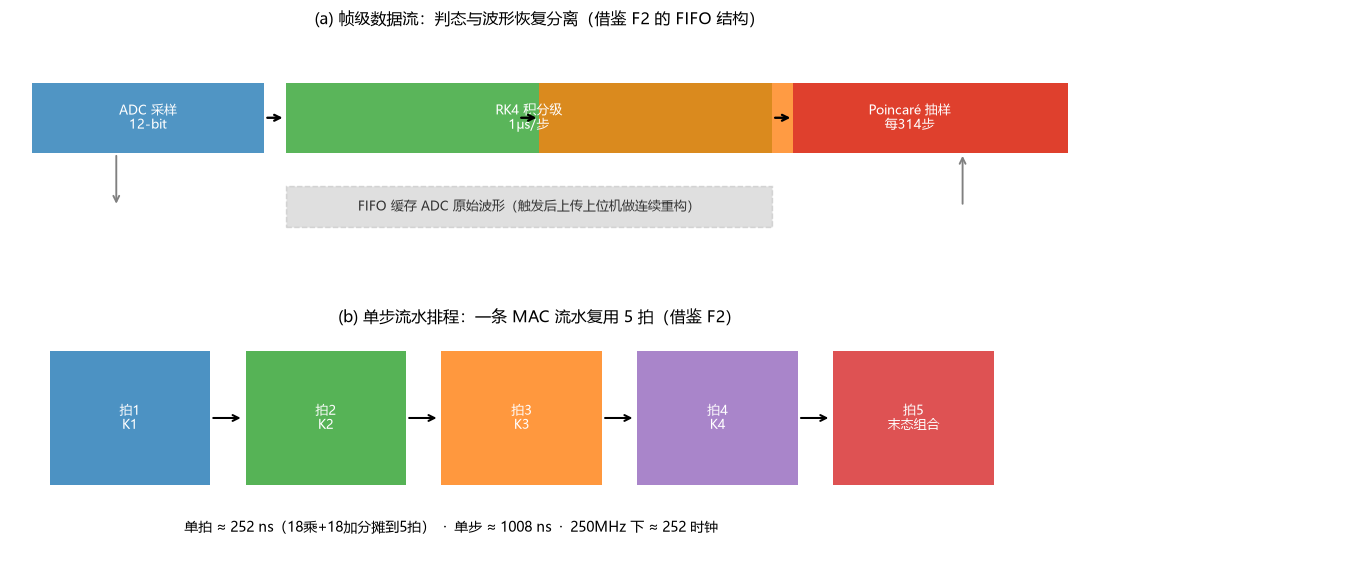

In [18]:
# 4.1 时序仿真图：帧级数据流 + 单步流水排程
fig = plt.figure(figsize=(13, 6.5))
gs = fig.add_gridspec(2, 1, height_ratios=[1.0, 1.1], hspace=0.42)

# --- 上：帧级数据流（三级流水 + FIFO 分离）
ax1 = fig.add_subplot(gs[0])
ax1.set_title('(a) 帧级数据流：判态与波形恢复分离（借鉴 F2 的 FIFO 结构）', fontsize=11)
stages = [
    (0.02, 0.22, 'ADC 采样\n12-bit', 'tab:blue'),
    (0.26, 0.46, 'RK4 积分级\n1μs/步', 'tab:green'),
    (0.50, 0.70, 'Poincaré 抽样\n每314步', 'tab:orange'),
    (0.74, 0.96, '帧级 pstd\n判态输出 0/1', 'tab:red'),
]
for x, w, label, color in stages:
    ax1.add_patch(plt.Rectangle((x, 0.42), w, 0.34, facecolor=color, alpha=0.78, edgecolor='none'))
    ax1.text(x + w/2, 0.59, label, ha='center', va='center', fontsize=9, color='white')
for x in [0.24, 0.48, 0.72]:
    ax1.annotate('', xy=(x+0.02, 0.59), xytext=(x, 0.59),
                 arrowprops=dict(arrowstyle='->', lw=1.6, color='black'))
# FIFO 旁路
ax1.add_patch(plt.Rectangle((0.26, 0.06), 0.46, 0.20, facecolor='grey', alpha=0.25, edgecolor='grey', ls='--'))
ax1.text(0.49, 0.16, 'FIFO 缓存 ADC 原始波形（触发后上传上位机做连续重构）',
         ha='center', va='center', fontsize=9, color='#333')
ax1.annotate('', xy=(0.10, 0.16), xytext=(0.10, 0.42),
             arrowprops=dict(arrowstyle='->', lw=1.3, color='grey'))
ax1.annotate('', xy=(0.90, 0.42), xytext=(0.90, 0.16),
             arrowprops=dict(arrowstyle='->', lw=1.3, color='grey'))
ax1.set_xlim(0, 1); ax1.set_ylim(0, 1); ax1.axis('off')

# --- 下：单步流水线排程（5 拍复用一条 MAC 流水）
ax2 = fig.add_subplot(gs[1])
ax2.set_title('(b) 单步流水排程：一条 MAC 流水复用 5 拍（借鉴 F2）', fontsize=11)
beats = ['拍1\nK1', '拍2\nK2', '拍3\nK3', '拍4\nK4', '拍5\n末态组合']
colors = ['tab:blue', 'tab:green', 'tab:orange', 'tab:purple', 'tab:red']
for j, (label, color) in enumerate(zip(beats, colors)):
    ax2.add_patch(plt.Rectangle((j, 0), 0.82, 1, facecolor=color, alpha=0.8, edgecolor='none'))
    ax2.text(j+0.41, 0.5, label, ha='center', va='center', fontsize=9, color='white')
    if j < 4:
        ax2.annotate('', xy=(j+0.99, 0.5), xytext=(j+0.82, 0.5),
                     arrowprops=dict(arrowstyle='->', lw=1.4, color='black'))
ax2.text(2.05, -0.35, f'单拍 ≈ {ITER_NS/N_STAGES-0:.0f} ns（18乘+18加分摊到5拍）  ·  单步 ≈ {ITER_NS:.0f} ns  ·  250MHz 下 ≈ {CYCLES:.0f} 时钟',
         ha='center', fontsize=9.5)
ax2.set_xlim(-0.2, 5.2); ax2.set_ylim(-0.55, 1.15); ax2.axis('off')

savefig('阶段5-时序仿真与数据流.png')
plt.show()

## 5｜与阶段 4 浮点指标对照 + 边界

**对照原则**：定点数字**不与文献横向比较**，只与本课题阶段 4 的浮点结果同条件对照（同 $\sigma=0.05$、$\gamma=0.02$、$h=0.02$、pstd 判据、H0 反解门限）。差异来源有三层，必须分清：**量化舍入（F≥12 时可忽略）→ 位宽不足（F≤8 时致命）→ 方法差异（旧 RK4 中间点取了整步，已修正）**。

**必须保留的三条边界**（写论文/答辩时主动说明）：
1. **无板级实测**：本阶段是定点数值仿真 + 工艺换算，不是综合报告；F2 的 24 ns/32 ns 与 1440 ns 是其 Zynq-7045 实测，本课题只借作换算锚点。
2. **观测窗不可压缩**：帧计算约 20–60 ms，但物理观测窗 400 s 是信号本身的时标；FPGA 再快也只是把"算一帧"从小时级压到毫秒级，**压不掉 400 s 的物理等待**。
3. **位宽决定"能不能用"，换平台仍要重扫**：F≥12 时浮点阈值可沿用；F≤8 时不是"重标定就能救"——H0 自己相变、门限塌缩，得先加位宽。换 FPGA / 换采样率仍需重扫 $\lambda_c$（采样步长变了，$h_1$ 跟着变）。

In [19]:
# 5.1 与阶段 4 浮点指标对照表
j4_path = OUT / '阶段4-检测性能与参数估计汇总.json'
j4 = json.load(open(j4_path, encoding='utf-8')) if j4_path.is_file() else None

compare = []
compare.append({
    '项目': '工作点 λ0',
    '阶段4浮点': '0.72（浮点阈值带 0.7334–0.7336）',
    '阶段5定点': f'F={F_DET} 可直接沿用（Pd={PD_Q12:.2f}）；F={F_LOW} 同一工作点 Pd={PD_Q8:.2f}',
})
compare.append({
    '项目': '等效阈值 λc',
    '阶段4浮点': '0.7335（0.001 步长精扫，T=1200s）',
    '阶段5定点': f'F={F_DET}: 精扫 ≈{fine_c["F12"]}（与浮点同格）；F={F_LOW}: ≈0.76 且 λ≈0.79 伪回弹',
})
compare.append({
    '项目': 'Pd（自身条件下）',
    '阶段4浮点': '0.92（σ=0.05, γ=0.02, T=400s, Pfa≤0.05）',
    '阶段5定点': f'F={F_DET}: {PD_Q12:.2f}；F={F_LOW}: {PD_Q8:.2f}（T={T_DET:.0f}s）',
})
compare.append({
    '项目': '最低可检测 SNR',
    '阶段4浮点': '−11.0 dB（白噪/1/f, T=400s）',
    '阶段5定点': '未重扫（需换平台后重标；不与文献 −18dB 比）',
})
compare.append({
    '项目': '单步计算时间',
    '阶段4浮点': '未估算（离线 Python）',
    '阶段5定点': f'{ITER_NS:.0f} ns/步 ≈ {CYCLES:.0f} 时钟 @250MHz（F2 工艺换算）',
})

print(f'{"项目":<16}{"阶段4浮点":<48}{"阶段5定点"}')
for row in compare:
    print(f'{row["项目"]:<16}{row["阶段4浮点"]:<48}{row["阶段5定点"]}')

项目              阶段4浮点                                           阶段5定点
工作点 λ0          0.72（浮点阈值带 0.7334–0.7336）                       F=12 可直接沿用（Pd=0.82）；F=8 同一工作点 Pd=0.42
等效阈值 λc         0.7335（0.001 步长精扫，T=1200s）                      F=12: 精扫 ≈0.734（与浮点同格）；F=8: ≈0.76 且 λ≈0.79 伪回弹
Pd（自身条件下）       0.92（σ=0.05, γ=0.02, T=400s, Pfa≤0.05）          F=12: 0.82；F=8: 0.42（T=300s）
最低可检测 SNR       −11.0 dB（白噪/1/f, T=400s）                        未重扫（需换平台后重标；不与文献 −18dB 比）
单步计算时间          未估算（离线 Python）                                  1008 ns/步 ≈ 252 时钟 @250MHz（F2 工艺换算）


In [20]:
# 5.2 JSON 汇总
summary = {
    'stage': 5,
    'boundary': '定点数值仿真 + F2 工艺换算，无 FPGA 板级实测；不与文献 SNR 横向比较',
    'condition': {
        'model': 'Duffing x\'\' + 0.5x\' - x^3 + x^5 = drive；RK4 h=0.02s',
        'q_format': 'Q2.F（2 位整数含符号 + F 位小数，W=2+F）',
        'word_scan_F': F_GRID,
        'lam_grid': LAM_GRID.tolist(),
        'T_scan_s': T_SIM, 'T_det_s': T_DET, 'sigma': SIGMA_DET, 'gamma': GAMMA_SIG,
        'NMC': NMC,
    },
    'word_length': {
        'lambda_c_by_F': {str(F): v for F, v in lam_c.items()},
        'float_lambda_c_coarse': next((float(l) for l, v in zip(LAM_GRID, fl_ref) if v < 0.1), None),
        'float_lambda_c_fine': 0.7335,
        'collapse_F': [F for F, v in collapse.items() if v],
        'no_transition_F': [F for F, v in no_transition.items() if v],
        'spurious_rebound_by_F': {str(F): v for F, v in spurious.items() if v is not None},
        'recommended_F': [10, 12],
        'note': ('F=4 塌缩(全程 pstd≈0 的假周期); F=6 相变消失; F=8 阈值漂到 0.76 且 λ=0.80 伪回弹;'
                 ' F=10 阈值 +0.001; F>=12 与浮点重合（0.001 步长精扫, T=1200s）'),
        'rk4_intermediate_step': 'k2/k3 取 h/2、k4 取 h；旧实现误用整步 h，把等效阈值推到 0.77',
        'fine_scan': {
            'lam_grid': LAM_FINE.tolist(),
            'T_s': 1200.0,
            'lambda_c': dict(fine_c),
            'pstd': {k: [round(x, 6) for x in v] for k, v in fine.items()},
            'note': ('T=1200s 仍是下界（阶段 2 经验：T=3000s 才全收敛）；'
                     '只用来说明定点与浮点同量级，不宣称精确值。'
                     '粗网格在 F>=14 处报的 0.75/0.76 是短窗伪影'),
        },
    },
    'detection_by_width': {
        'lam0_grid': LAM0_GRID.tolist(),
        'F_list': F_LIST,
        'pd_by_lam0': {str(F): dict(zip([str(x) for x in LAM0_GRID], [round(v, 3) for v in pd_map[F]]))
                       for F in F_LIST},
        'gate_by_lam0': {str(F): [round(g, 4) for g in gate_map[F]] for F in F_LIST},
        'h0_median_by_F': {str(F): [round(a, 4) for a, b in med_map[F]] for F in F_LIST},
        'h1_median_by_F': {str(F): [round(b, 4) for a, b in med_map[F]] for F in F_LIST},
        'float_workpoint_lam0': LAM0_FLOAT,
        'pd_at_float_workpoint': {str(F): round(pd_map[F][i72], 3) for F in F_LIST},
        'best_lam0_F12': LAM0_BEST,
        'pd_at_best_F12': round(PD_BEST, 3),
        'conclusion': ('F>=12 时浮点工作点 λ0=0.72 可直接沿用；F=8 时 H0 自身已相变、'
                       '门限塌缩，重标定也救不回来'),
    },
    'resource_timing': {
        'basis': 'F2 实测 Zynq-7045 250MHz：24ns/乘、32ns/加；线性换算，非本机综合',
        'ops_per_step': {'mul': OPS_MUL, 'add': OPS_ADD, 'total': OPS_MUL + OPS_ADD},
        'iter_ns': round(ITER_NS, 1),
        'cycles_at_250mhz': round(CYCLES, 0),
        'steps_per_frame': STEPS_PER_FRAME,
        'frame_ms_single': round(FRAME_MS_PAR, 2),
        'frame_ms_tdm3': round(FRAME_MS_TDM, 2),
        'array_choice': 'TDM 单核 + FIFO（计算量远小于物理观测窗，省资源优先）',
        'judgement_stage': 'Poincaré 抽样后帧级 pstd；波形恢复走 FIFO 旁路，与判态分离',
    },
    'comparison_with_stage4': compare,
    'notes': [
        '量化本身几乎不动等效阈值：F>=12 与浮点重合在 0.7335；漂移由位宽不足引起，不是定点的普遍代价',
        'F=4 塌缩/F=6 无相变/F=8 伪回弹且阈值漂到 0.76；F=10~12 才是甜点区',
        'RK4 的 k2/k3 必须取 h/2；旧实现误用整步 h，把阈值推到 0.77（本次修正）',
        '帧计算 ms 级 vs 物理窗 400s：计算不是瓶颈，观测时长才是',
        '换 FPGA/字长/采样率都要重扫 λc；H0 反解门限纪律沿用阶段 4',
        'F2 的 −18dB 与本课题 −11dB 条件全不同，不可横向比较',
    ],
}
jp = OUT / '阶段5-定点化与资源时序汇总.json'
jp.write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
print('[JSON]', jp)
print('\n=== 阶段 5 结论 ===')
print(f'推荐字长 F=10~12；F={F_DET} 精扫阈值 ≈{fine_c["F12"]}（浮点 {fine_c["浮点"]}，同格）')
print(f'浮点工作点 λ0={LAM0_FLOAT}: F={F_DET} 下 Pd={PD_Q12:.2f}（可直接沿用）；'
      f'F={F_LOW} 下 Pd={PD_Q8:.2f}')
print(f'单步 {ITER_NS:.0f}ns ≈ {CYCLES:.0f} 时钟；单帧 {FRAME_MS_PAR:.0f}ms ≪ 400s 物理窗')

[JSON] C:\Users\22902\WorkBuddy\毕设\复现输出\阶段5-定点化与资源时序汇总.json

=== 阶段 5 结论 ===
推荐字长 F=10~12；F=12 精扫阈值 ≈0.734（浮点 0.734，同格）
浮点工作点 λ0=0.72: F=12 下 Pd=0.82（可直接沿用）；F=8 下 Pd=0.42
单步 1008ns ≈ 252 时钟；单帧 20ms ≪ 400s 物理窗
